# Does μ̂ predict next month's factor returns? (K = 30, τ = 10, in-sample)

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from eda_data import *
from src.config import CENTROIDS_NPZ, CHARS_CLEAN_PARQUET, MIN_HISTORY_MONTHS, TAU, TARGET_COL, feature_cols
from src.factors.build_panel import load_panel

factor_returns, _ = load_panel()
F = factor_returns.drop("DATE").to_numpy()
dates = factor_returns["DATE"].to_numpy()
z = np.load(CENTROIDS_NPZ); C = z["centroids"]
assert np.array_equal(z["dates"], dates)
df = pl.read_parquet(CHARS_CLEAN_PARQUET).filter(pl.col("DATE") <= IS_END_DATE)
features = feature_cols(df.columns)
groups = [g for _, g in df.group_by("DATE", maintain_order=True)]
Xn = [g.select(features).to_numpy() for g in groups]
Xn = [X / np.linalg.norm(X, axis=1, keepdims=True) for X in Xn]
R = [g[TARGET_COL].to_numpy() for g in groups]
T, K = F.shape
print(T, "months,", K, "factors, τ =", TAU)

191 months, 30 factors, τ = 10


## Rebuilt history: for each month t, every earlier month's factor returns using month t's centroids

In [2]:
def factor_returns_with(centroids, X, r, tau=TAU):
    P = np.exp(tau * (X @ centroids.T - (X @ centroids.T).max(axis=1, keepdims=True)))
    P /= P.sum(axis=1, keepdims=True)
    W = P - P.mean(axis=0)
    return (W / np.abs(W).sum(axis=0)).T @ r

rebuilt = {t: np.array([factor_returns_with(C[t], Xn[s], R[s]) for s in range(t)]) for t in range(MIN_HISTORY_MONTHS, T)}
print("check: rebuilding month t with its own centroids gives the stored return:",
      np.allclose(factor_returns_with(C[100], Xn[100], R[100]), F[100]))

check: rebuilding month t with its own centroids gives the stored return: True


## Stored vs rebuilt history: correlation of each factor's last 36 months

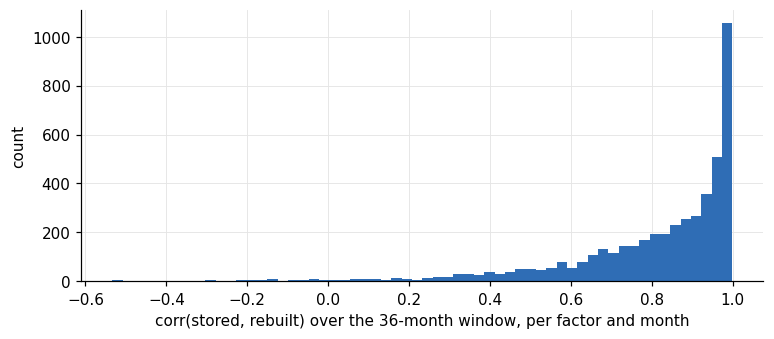

median 0.883, 10th pct 0.509, share below 0.8 35.2%


In [3]:
corrs = [np.corrcoef(F[t - 36:t, k], rebuilt[t][t - 36:t, k])[0, 1] for t in rebuilt for k in range(K)]
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(corrs, bins=60, color=BLUE)
ax.set_xlabel("corr(stored, rebuilt) over the 36-month window, per factor and month"); ax.set_ylabel("count"); plt.show()
print(f"median {np.median(corrs):.3f}, 10th pct {np.percentile(corrs, 10):.3f}, share below 0.8 {np.mean(np.array(corrs) < 0.8):.1%}")

## Factor IC and sign accuracy of μ̂ for each window

In [4]:
WINDOWS = [1, 3, 6, 12, 24, 36, 60, "expanding"]
eval_months = list(range(MIN_HISTORY_MONTHS, T))

def mu_hat(hist, L):
    return hist.mean(axis=0) if L == "expanding" else hist[-L:].mean(axis=0)

rows = []
for source in ["stored", "rebuilt"]:
    for L in WINDOWS:
        for t in eval_months:
            hist = F[:t] if source == "stored" else rebuilt[t]
            m = mu_hat(hist, L)
            rows.append({"source": source, "window": str(L), "DATE": int(dates[t]),
                         "ic": spearmanr(m, F[t]).statistic, "sign_hit": np.mean(np.sign(m) == np.sign(F[t]))})
res = pl.DataFrame(rows)
def summarise(frame):
    return frame.group_by("source", "window", maintain_order=True).agg(
        pl.col("ic").mean().alias("ic_mean"), (pl.col("ic").mean() / (pl.col("ic").std() / pl.len().sqrt())).alias("ic_t"),
        pl.col("sign_hit").mean().alias("sign_hit_rate"))
summary = summarise(res)
summary

source,window,ic_mean,ic_t,sign_hit_rate
str,str,f64,f64,f64
"""stored""","""1""",0.0886,2.6492,0.5335
"""stored""","""3""",0.0556,1.6408,0.5222
"""stored""","""6""",0.0691,2.0683,0.5299
"""stored""","""12""",0.0966,3.0602,0.5426
"""stored""","""24""",0.0644,2.2450,0.5185
"""stored""","""36""",0.0780,3.1858,0.5224
"""stored""","""60""",0.0720,3.6563,0.5271
"""stored""","""expanding""",0.0407,2.1084,0.5131
"""rebuilt""","""1""",0.0887,2.6654,0.5372


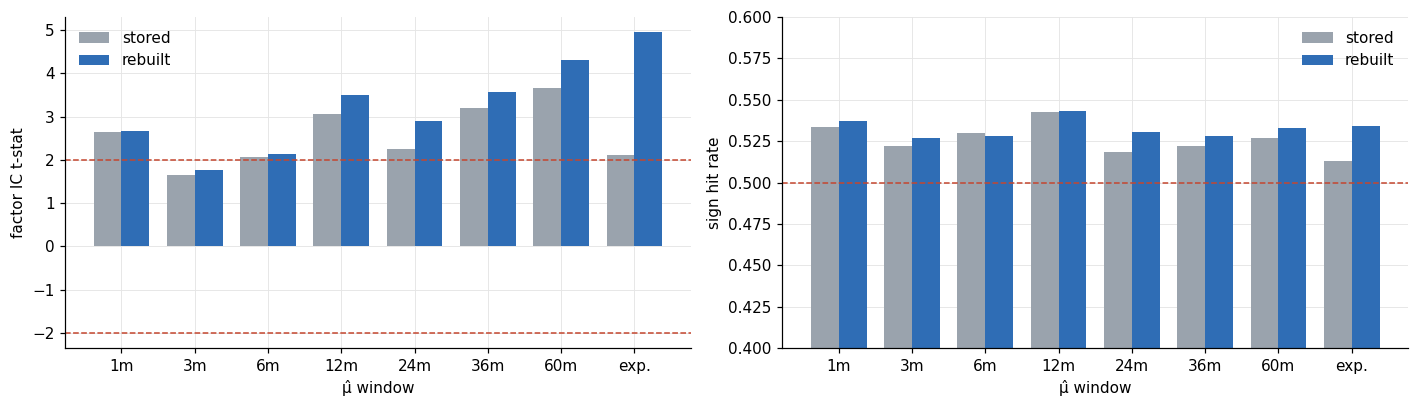

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(len(WINDOWS)); w = 0.38
for i, (source, color) in enumerate([("stored", GREY), ("rebuilt", BLUE)]):
    s = summary.filter(pl.col("source") == source)
    axes[0].bar(x + (i - 0.5) * w, s["ic_t"], w, color=color, label=source)
    axes[1].bar(x + (i - 0.5) * w, s["sign_hit_rate"], w, color=color, label=source)
for v in (-2, 2):
    axes[0].axhline(v, color="#c4462f", lw=1, ls="--")
axes[1].axhline(0.5, color="#c4462f", lw=1, ls="--")
axes[0].set_ylabel("factor IC t-stat"); axes[1].set_ylabel("sign hit rate"); axes[1].set_ylim(0.4, 0.6)
for ax in axes:
    ax.set_xticks(x, [f"{L}m" if L != "expanding" else "exp." for L in WINDOWS]); ax.set_xlabel("μ̂ window"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

## Stability: 1993–1999 vs 2000–2005

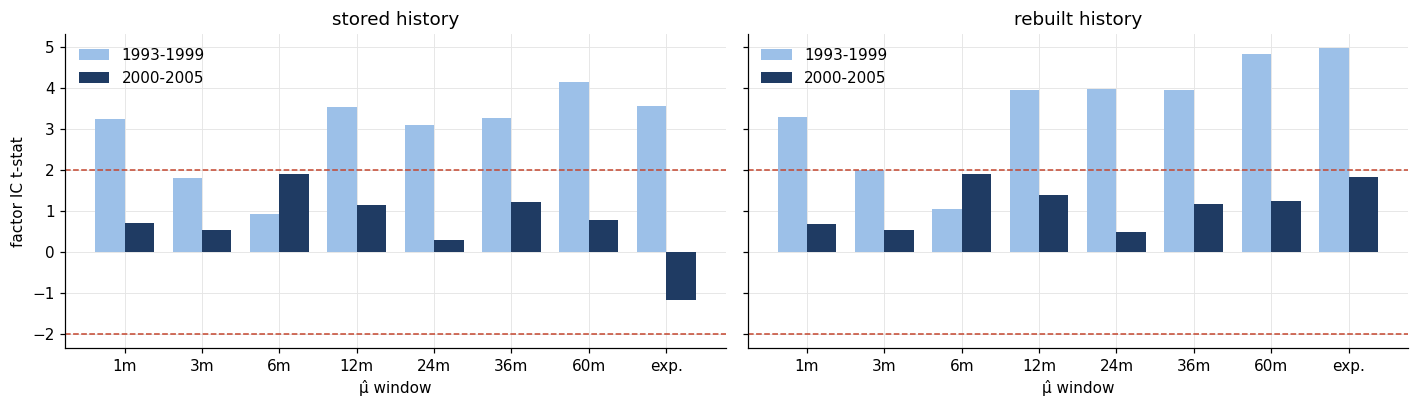

source,window,ic_mean,ic_t,sign_hit_rate,period
str,str,f64,f64,f64,str
"""rebuilt""","""1""",0.1328,3.3015,0.5510,"""1993-1999"""
"""rebuilt""","""expanding""",0.1589,4.9769,0.5494,"""1993-1999"""
"""rebuilt""","""60""",0.1544,4.8289,0.5558,"""1993-1999"""
"""rebuilt""","""36""",0.1411,3.9563,0.5442,"""1993-1999"""
"""rebuilt""","""24""",0.1452,3.9881,0.5446,"""1993-1999"""
"""rebuilt""","""12""",0.1459,3.9589,0.5526,"""1993-1999"""
"""rebuilt""","""6""",0.0432,1.0411,0.5104,"""1993-1999"""
"""rebuilt""","""3""",0.0879,2.0028,0.5373,"""1993-1999"""
"""rebuilt""","""1""",0.0380,0.6984,0.5213,"""2000-2005"""


In [6]:
halves = pl.concat([summarise(res.filter(pl.col("DATE") < 20000101)).with_columns(pl.lit("1993-1999").alias("period")),
                    summarise(res.filter(pl.col("DATE") >= 20000101)).with_columns(pl.lit("2000-2005").alias("period"))])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, source in zip(axes, ["stored", "rebuilt"]):
    for i, (period, color) in enumerate([("1993-1999", "#9cc0e8"), ("2000-2005", "#1f3b63")]):
        s = halves.filter((pl.col("source") == source) & (pl.col("period") == period))
        ax.bar(x + (i - 0.5) * w, s["ic_t"], w, color=color, label=period)
    for v in (-2, 2):
        ax.axhline(v, color="#c4462f", lw=1, ls="--")
    ax.set_title(f"{source} history"); ax.set_xticks(x, [f"{L}m" if L != "expanding" else "exp." for L in WINDOWS])
    ax.set_xlabel("μ̂ window"); ax.legend(frameon=False)
axes[0].set_ylabel("factor IC t-stat"); plt.tight_layout(); plt.show()
halves.sort("source", "period")

## Cumulative factor IC over time (12-month window)

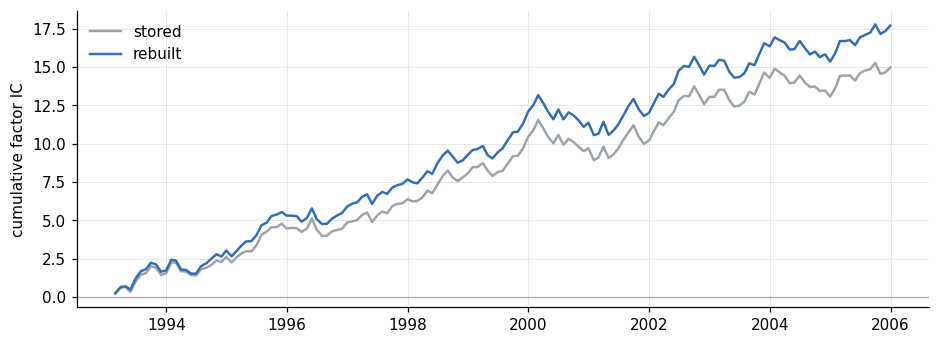

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
for source, color in [("stored", GREY), ("rebuilt", BLUE)]:
    s = res.filter((pl.col("source") == source) & (pl.col("window") == "12")).sort("DATE")
    ax.plot(s["DATE"].cast(pl.String).str.to_date("%Y%m%d"), s["ic"].cum_sum(), color=color, lw=1.6, label=source)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_ylabel("cumulative factor IC"); ax.legend(frameon=False); plt.show()